# Exercise 1

In dieser Übung sollen Bilder aus einer verschachtelten Verzeichnisstruktur eingelesen werden und Metadaten aus dem Pfad bzw. dem Dateinamen ausgelesen.

Die Bilder befinden sich in zwei Verzeichnissen train und test, jeweils für die Trainings- und Testdaten.


Der Aufbau ist wie folgt:

```
data/
|---{train, test}/
|---|---image-{n}-{l}.jpeg
|---|---...
```

*n* ist eine zufällige Zahl, *l* das Label für das jeweilige Bild.

In [56]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

In [57]:
data_directory = "data"
TRAIN_DIRECTORY = os.path.join(data_directory, "train")
TEST_DIRECTORY = os.path.join(data_directory, "test")

Lesen Sie folgende Informationen zu den Bildern ein: Bild-Pfad, Split und Label:

In [82]:
walk_train = os.listdir(TRAIN_DIRECTORY)
walk_test = os.listdir(TEST_DIRECTORY)
labels_train = [None] * len(walk_train)
labels_test = [None] * len(walk_test)

for i, name in enumerate(walk_train):
    x1 = name.split(".jpeg")[0].split("-")[-1]
    labels_train[i] = 1 if x1 == "p" else 0
    
for i, name in enumerate(walk_test):
    x1 = name.split(".jpeg")[0].split("-")[-1]
    labels_test[i] = 1 if x1 == "p" else 0

Konvertieren Sie die Labels in numerische Werte 0 und 1:

In [83]:
print(labels_test)
print(labels_train)

[0, 1, 1]
[0, 1, 1, 0, 0, 0]


Erstellen sie einen Pandas DataFrame für die extrahierten Bildpfade, Splits und Labels. Fügen Sie die numerischen Labels als Spalte zum erstellten DataFrame hinzu:

In [81]:
paths = walk_train + (walk_test)
labels = labels_train + (labels_test)
splits = ["train"] * len(walk_train) + ["test"] * len(walk_test)

df = pd.DataFrame({
    "path": paths,
    "split": splits,
    "label": labels
})
df

,path,split,label
0,image-3-n.jpeg,train,0
1,image-4-p.jpeg,train,1
2,image-5-p.jpeg,train,1
3,image-6-n.jpeg,train,0
4,image-8-n.jpeg,train,0
5,image-9-n.jpeg,train,0
6,image-1-n.jpeg,test,0
7,image-2-p.jpeg,test,1
8,image-7-p.jpeg,test,1


Plotten Sie die Anzahl der vorkommenden Labels jeweils für den Trainings- und Testdatensatz als Barplot (x-Achse: Label, y-Achse: Anzahl der Labels):

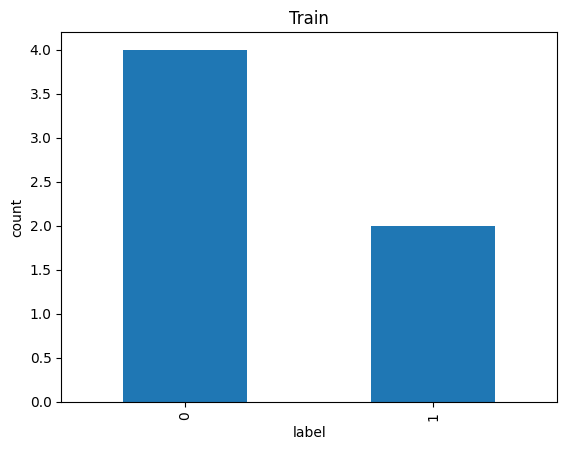

In [61]:
train_df = df[df["split"] == "train"]

# count labels and plot
train_df["label"].value_counts().plot(kind="bar", title="Train")

plt.xlabel("label")
plt.ylabel("count")
plt.show()

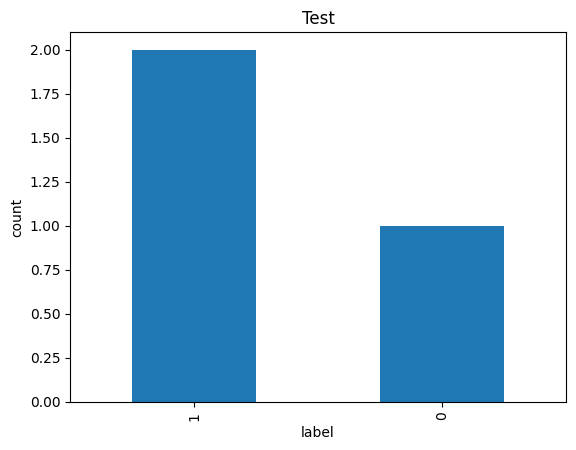

In [62]:
test_df = df[df["split"] == "test"]

# count labels and plot
test_df["label"].value_counts().plot(kind="bar", title="Test")

plt.xlabel("label")
plt.ylabel("count")
plt.show()

Plotten Sie für jedes Label ein Beispiel Bild jeweils aus dem Trainings- und Testdatensatz:

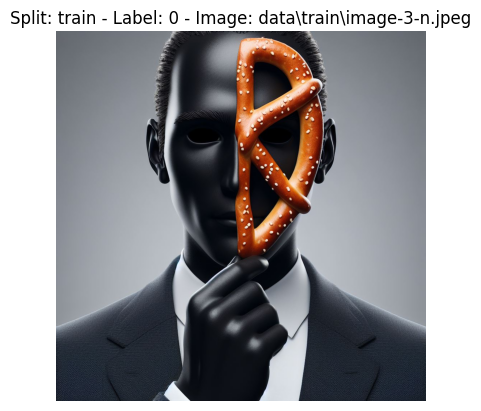

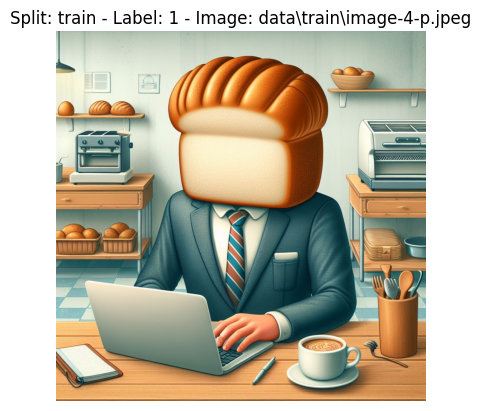

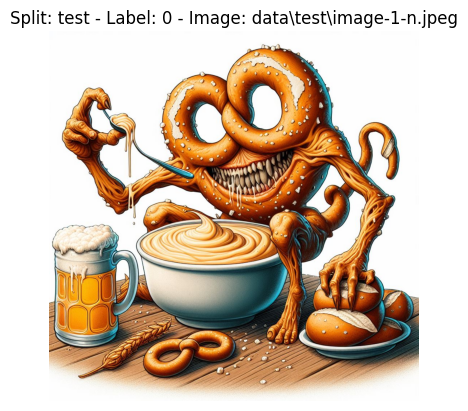

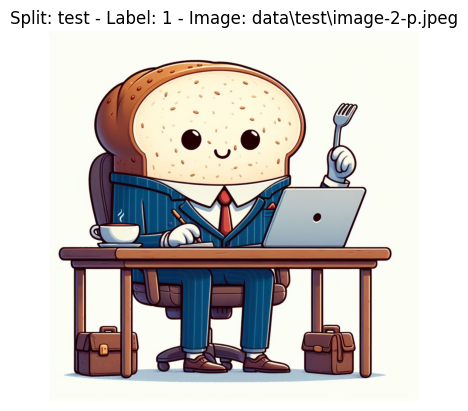

In [80]:
def display(path, split, label):
    img = mpimg.imread(path)
    plt.imshow(img)
    plt.title(f"Split: {split} - Label: {label} - Image: {path}")
    plt.axis("off")
    plt.show()

test_df = df[df["split"] == "test"]

def plot(kind: str):
    labels_at = globals()["labels_" + kind]
    walk_at = globals() ["walk_" + kind]
    root_at = os.path.join(data_directory, kind)
    one_done =False
    zero_done = False
    for i, label in enumerate(labels_at):
        if label == 0 and not zero_done:
            path = os.path.join(root_at, walk_at[i])
            display(path, kind, 0)
            zero_done = True
        if label == 1 and not one_done:
            path = os.path.join(root_at, walk_at[i])
            display(path, kind, 1)
            one_done = True
        if zero_done and one_done:
            break
    
plot("train")
plot("test")